### Import libraries/functions

In [1]:
from functions.get_DLRbiomass import *
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

### DLR-Timeseries

In [23]:
years = [2017, 2018, 2019, 2020, 2021]
arrays = []

for y in years:
    ds = get_biomass_fromDLR(year=y)
    arrays.append(ds.read(1))
    ds.close()
stack = np.stack(arrays, axis=0)

annual_means_AGBD = np.array([np.nanmean(np.where(stack[i] > 0, stack[i], np.nan)) for i in range(len(years))])

### Convert Mg/ha to Mg

In [29]:
area = gpd.read_file("/home/berberic/Documents/data/training_data2/bonn_trainingdata/bonn_forest.geojson").area / 10000

annual_means_AGB = annual_means_AGBD * float(area.iloc[0])

[1193035.77157166 1186522.69681049 1189637.0027228  1119142.2228883
 1049372.9390186 ]


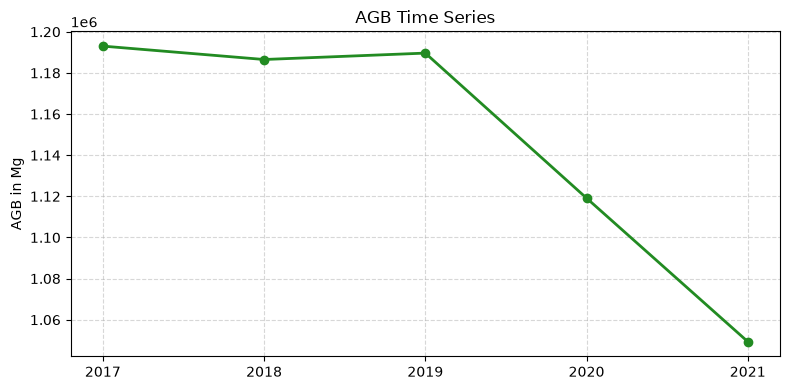

In [33]:
plt.figure(figsize=(8, 4))
plt.plot(years, annual_means_AGB, marker="o", linestyle="-", color="forestgreen", linewidth=2)

plt.title("AGB Time Series")
plt.ylabel("AGB in Mg")
plt.xticks(years)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()